# Librerias y constantes

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

M_N = 939.56542194 #MeV
M_P = 938.27208943 #MeV
Q = M_N - M_P #MeV
T0 = 7 #MeV
G = 6.71E-45 #MeV-2
HBAR = 6.582119569e-22  # MeV*s
H1 = np.sqrt((44*np.pi*G)/3) * Q**2 #MeV
TAU_N = 886 / HBAR #MeV-1

# Resuelvo la ecuación

La ecuación de Boltzmann a resolver es la siguiente:
$$\frac{dX_n}{dx} = \frac{x\lambda_{np}}{H(x = 1)}[e^{-x} - X_n(1 + e^{-x})]$$

Donde:
* $\lambda_{np} = \frac{225}{\tau_n x^5}(12 + 6x + x^2)$
* $H(x = 1) = \sqrt{\frac{44\pi G}{3}}Q^2$

In [47]:
# Condiciones iniciales
np_nn0 = np.exp( (M_N - M_P)/ T0)
X0 = 1/(1 + np_nn0)
x0 = Q/T0
xF = 70 # TBBN ~ 0.08MeV

#Lado derecho

def f(x, X):
    l_np = (225 / TAU_N / x**5) * (12 + 6*x + x**2)
    pref = x*l_np / H1
    fact = np.exp(-x) - (X*(1 + np.exp(-x)))

    return pref*fact

sol = solve_ivp(f, [x0, xF], np.array([X0]), dense_output=True, max_step = .01)

# Resultados

Con este *solver* obtuve $X_n$ y $x$, pero me interesa graficar $n_n/n_p$ en función de $T$. Para esto invierto la relación entree $X_n$ y $n_p /n_n$:

$$\frac{n_n}{n_p} = \frac{X_n}{1 - X_n}$$

$$T = \frac{Q}{x}$$

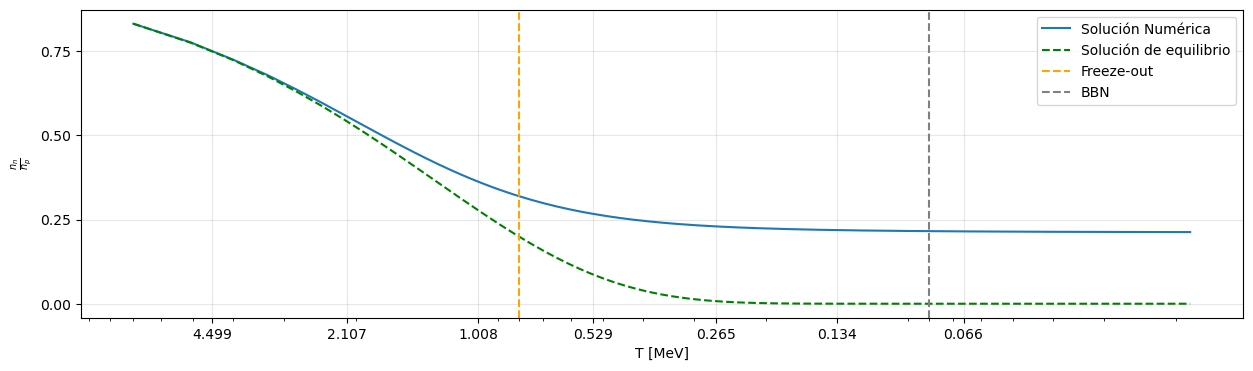

In [ ]:
x = np.linspace(x0, xF, 1_000)
X_n = sol.sol(x)[0]

#Invierto las relaciones
nn_np = X_n / (1 - X_n)
T = Q/x

# Solución del equilibrio
equilibrio = np.exp(-Q/T)

fig, ax = plt.subplots()

ax.plot(T, nn_np, label = 'Solución Numérica')
ax.plot(T, equilibrio, label = 'Solución de equilibrio',
        color = 'green', linestyle = '--')
ax.axvline(.8, label = 'Freeze-out', linestyle = '--',
           color = 'orange')
ax.axvline(.08, label = 'BBN', linestyle = '--',
           color = 'gray')

T_ticks = [0.066, 0.134, 0.265, 0.529, 1.008, 2.107, 4.499] #MeV
ax.set(xlabel = 'T [MeV]', ylabel = r'$\frac{n_n}{n_p}$',
       yticks = np.arange(0, 1, .25), 
       xscale = 'log', xticks = T_ticks)
ax.set_xticklabels(str(val) for val in T_ticks)
ax.xaxis.set_inverted(True)
ax.grid(alpha = .3)
ax.legend()
